## PCA and Text Analysis

This assignment involves processing real e-mails, some of which are scams.

(Fair warning: Some of these scam e-mails have offensive content. If you start reading the e-mail text or the token data, you might read something offensive. If that's a problem, feel free to e-mail us, and we can talk about it and discuss how to proceed with alternative tasks.)

**Q1.**

**Tokens**: The individual words or symbols that create text data like emails. Natural Language Processing is primarily about analyzing the frequency and co-occurrence of tokens.

We aggregated all the emails into a single vector, and removed the punctuation and very common words (e.g. "the"). Run the below code chunk to open it, and use the Counter class to look at the most common words:

In [2]:
!git clone https://github.com/Matthew-Calvario/A05-pca.git

Cloning into 'A05-pca'...
remote: Enumerating objects: 16, done.
remote: Counting objects: 100% (6/6), done.
remote: Compressing objects: 100% (5/5), done.
remote: Total 16 (delta 3), reused 1 (delta 1), pack-reused 10 (from 1)
Receiving objects: 100% (16/16), 1.94 MiB | 13.15 MiB/s, done.
Resolving deltas: 100% (3/3), done.


In [3]:
import pickle

with open('A05-pca/data/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)

from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()
print(token_freq)

[('new', 1365), ('date', 1202), ('get', 1052), ('please', 1022), ('enron', 927), ('like', 923), ('2002', 869), ('would', 806), ('one', 798), ('message', 795), ('call', 740), ('free', 691), ('software', 680), ('dear', 651), ('know', 644), ('email', 629), ('url:', 625), ('time', 609), ('start', 604), ('linguistics', 598), ('online', 591), ('need', 587), ('wrote:', 585), ('see', 554), ('conference', 553), ('language', 550), ('want', 548), ('empty', 546), ('hourahead', 526), ('list', 523), ('attached', 515), ('hello', 501), ('university', 500), ('2001', 489), ('information', 473), ('vince', 473), ('may', 461), ('good', 449), ('following', 448), ('hour', 446), ('2000', 442), ('business', 442), ('save', 423), ('first', 423), ('click', 423), ('best', 423), ('make', 421), ('com', 413), ('original', 410), ('offer', 405), ('meeting', 403), ('thanks', 397), ('mail', 395), ('use', 389), ('find', 386), ('papers', 383), ('http', 378), ('sent', 375), ('available', 373), ('last', 372), ('update', 363)

Plot a histogram of the occurrences of tokens.
What do you notice about the frequency of occurrence of different tokens? How does it look?

**Q2.**

Load `Phishing_clean.parquet`. This is the text from the e-mails broken into the most common 2,711 tokens and one-hot-encoded as features/covariates. So each row is an e-mail, the `Email Type` takes the value 1 if it's a scam and 0 otherwise, and every other column is a word or symbol that occurs in at least 15 e-mails.

1. Perform an 80/20 train-test split of the data.
2. Run a regression of $y$ on the one-hot-encoded emails. What is the $R^2$ on the test set? On the training set?
3. What words have the largest coefficients in absolute value and most strongly influence predictions?

**Q3.**

Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, `Email Type`) and perform a principal components analysis decomposition with two components. Plot the first two principal components in a scatter plot, and hue the points by whether they are a phishing scam or not. Do you notice any patterns?

**Q4.**

Run a linear regression of $y$ on the first 2,610 principal components of $X$. What is the $R^2$ on the training and test sets?
How does this performance compare to the linear regression?

**Q5.**

Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Matthew Calvario

**Date:** 10/19/26

In [ ]:
# Your Phase 1 solution to the problem goes here.

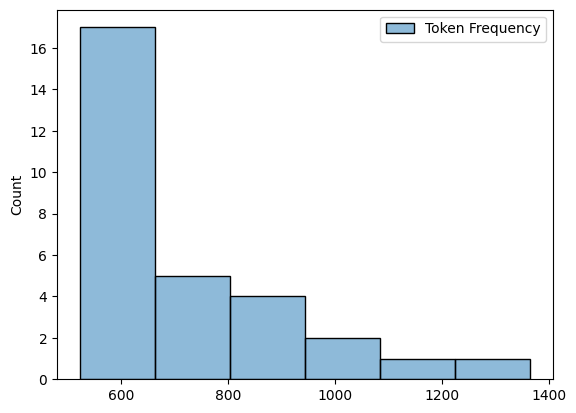


From the histogram, one can see that the freuqency of occurrence for different tokens takes the shape
of a long-tail curve, starting relatively high quickly and then sloping down with each bin. Thus, the frequency
of each token diminishes quickly with the first few and then settles into less extreme dips in count.

R-squared Test: 0.6659
intercept: 0.4821
R-squared Train: 0.767
                Feature  Coefficient
740           localized     0.824350
2362            thermal     0.747006
851             crawler     0.696167
1406         helvetica,     0.598560
906               aging     0.594956
...                 ...          ...
2657              zdnet    -0.560954
1494         retrieving    -0.573761
2242              gray;    -0.574480
1504  background-image:    -0.622909
835        intervention    -1.259257

[2711 rows x 2 columns]

The words with the largest coefficients and, thus, the strongest influence on the predictions,
are: localized, thermal, crawler, helvetica, and agin

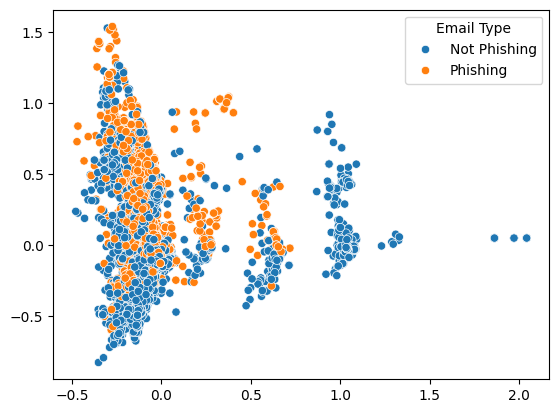

In [4]:
# Q1.

import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

# Convert token frequency list into dataframe, then us
df = pd.DataFrame(token_freq, columns=['Token Name', 'Token Frequency'])
df_filtered = df.head(30)

# Use the New "Token Frequency" Column for Count
sns.histplot(data=df_filtered)

# Display the plot
plt.show()

print("""
From the histogram, one can see that the freuqency of occurrence for different tokens takes the shape
of a long-tail curve, starting relatively high quickly and then sloping down with each bin. Thus, the frequency
of each token diminishes quickly with the first few and then settles into less extreme dips in count.
""")
# Q2.

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

df_phish = pd.read_parquet("A05-pca/data/Phishing_clean.parquet")
df_phish.describe()

# X Features
X = df_phish.drop(columns='Email Type')

# y target vector Email Type
y = df_phish['Email Type']

# Split Training Set
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

sk_fit = LinearRegression().fit(X_train, y_train)

print("R-squared Test:", round(sk_fit.score(X_test, y_test), 4))
print("intercept:", round(sk_fit.intercept_, 4))
print("R-squared Train:", round(sk_fit.score(X_train, y_train), 4))

# Create a clean and sortable DataFrame
coef_df = pd.DataFrame({
    'Feature': sk_fit.feature_names_in_,
    'Coefficient': sk_fit.coef_
}).sort_values(by='Coefficient', ascending=False)

print(coef_df)

coefficients = pd.Series(sk_fit.coef_, index=X_train.columns).round(4)
coefficients.sort_values(key=abs, ascending=False).head(10)

print("""
The words with the largest coefficients and, thus, the strongest influence on the predictions,
are: localized, thermal, crawler, helvetica, and aging.""")

# Q3.

from sklearn.decomposition import PCA
pca = PCA(n_components=2).fit(X)
X_pca_sklearn = pca.transform(X)
print("Rows and score columns:", X_pca_sklearn.shape)
print("Sklearn:", pca.explained_variance_ratio_.round(3))

sns.scatterplot(x=X_pca_sklearn[:, 0], y=X_pca_sklearn[:, 1],
                hue=pd.Series(y).map({0: 'Not Phishing', 1: 'Phishing'})) # Re-labeling ones and zeroes into "Not Phishing" and "Phishing" respectively

print("""
The PCA scatter displays significant overlap between phishing and non-phishing emails based on the two Principle
Components used--this is most evident near PC1 = 0, where several "Not Phishing" and "Phishing" labels are clumped
on the axis. Given that the PCA explained variance was small for both--0.011 and 0.009 for PC1 and PC2 respectively--
this overlap present at low percentages indiciates that other dimensions may be more indicative of the emails' variance.
That being said, some distinct patterns emerge; for example, non-phishing emails tend to dominate clusters farther to the right
of the PC1 axis. Additionally, phishing emails appear to be more concentrated in upper portions of the PC2 cluster. As a whole,
however, these two principal components provided limited separation between phishing and non-phishing emails.
""")

# Q4.


# X Features (Use X original data)
X_pca = X

# y target vector Email Type (same from earlier)


# Split Training Set
X_train_pca, X_test_pca, y_train_pca, y_test_pca = train_test_split(
    X_pca, y, test_size=0.2, random_state=42
)

pca = PCA(n_components=2610).fit(X_train)
X_train_pca = pca.transform(X_train)
X_test_pca = pca.transform(X_test)
print("Rows and score columns:", X_train_pca.shape)


sk_fit_pca = LinearRegression().fit(X_train_pca, y_train_pca)
print("R-squared Test:", round(sk_fit_pca.score(X_test_pca, y_test_pca), 4))
print("intercept:", round(sk_fit_pca.intercept_, 4))
print("R-squared Train:", round(sk_fit_pca.score(X_train_pca, y_train_pca), 4))

print("""
Compared with linear regression prior to principal components, the R-squared Test and Train Results
are practically identical, with only the intercept changing noticeably from 0.4821 to 0.3924.
""")



Question 5. With thousands of dimensions like found in this dataset, using PCA filters out noise or features that do not contribute as much to the underlying patterns whilst retaining the variance. This can aid with computational costs by removing unnecessary information in processing; it can also aid in reducing overfitting so long as the number of principle components is appreciably smaller than the original dataset's feature count.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** aa537735f750449e5b01205b87b9c4c6d3c4f3ad
- **AI tool and model used:** GPT-6

### *Prompts used

1. Please review my existing Phase 1 code and responses alongside the original assignment instructions and suggest improvements for Phase 2. Check for basic errors (typos, logic, formatting, calculations, etc.), and make sure I've fully and accurately answered every question, including any requirements for visuals, computations, written explanations, and interpretations of results. Also look for ways to improve code efficiency, readability, and overall quality, as well as alternative approaches I may not have considered in my original solution (Though remain in the scope of the questions of the problem; do not deviate to techniques that do not directly answer the question). Please number each proposed change (Change 1, Change 2, etc.) and explain what should be changed and why, so I can directly copy and paste your suggestions into my Phase 2 documentation. Distinguish between necessary fixes and optional improvements, and focus on specific changes rather than rewriting my entire solution. Final important note: For qualitative, written answers, DO NOT alter the original sentiment and structure of my thought, but simply suggest improvements to precision and accuracy--avoid changing the original idea/interpretation as much as possible.
2. In regard to Change 1, will this affect the interpretation of the visualization by any substantial amount?
(Response: No, I wouldn't expect Change 1 to substantially alter your overall interpretation. In fact, it should reinforce your original conclusion about the long-tailed distribution of token frequencies.

The main difference is what the visualization represents:
- Original histogram (top 30 tokens): Focuses exclusively on the most frequently occurring tokens, excluding the numerous less-common tokens.
- Revised histogram (all tokens): Shows the complete frequency distribution, likely emphasizing how most tokens occur relatively infrequently while a small number occur very frequently.
What stays the same?
Your original conclusion that token frequencies exhibit a long-tailed distribution, with relatively few common tokens and many less-common tokens, remains appropriate.
What should change?
Your description of frequencies decreasing with each successive bin should be modified. A histogram displays how many tokens fall within each frequency interval, rather than ranking individual tokens from most to least frequent.)
3. Please incorporate the changes following changes except for the following: Change 10 and 12. For Change 1, I would like to modify the suggestion by not proceeding with using a logarithmic scale; all other parts of the change are welcome. When incorporating the changes, keep the structure of the original phase 1 code, with as minimal changes as possible--they should only be augmentations of what was previously established.



### AI-Proposed Changes

**Change 1 — Q1: Correct the Token Frequency Histogram (Necessary)**  
Replace the histogram of only the 30 most frequent tokens with a histogram displaying the frequency distribution of all unique tokens. Explicitly specify `x='Token Frequency'` in `sns.histplot()`, and consider using a logarithmic horizontal scale to better represent the long-tailed distribution. This directly addresses the assignment's requirement to visualize overall token occurrences.

**Change 2 — Q1: Refine the Histogram Interpretation (Necessary)**  
Revise the written explanation to describe the distribution as highly right-skewed and long-tailed, with most unique tokens occurring infrequently and relatively few tokens occurring very frequently. Avoid describing the histogram as frequencies decreasing from one bin to the next, since that interpretation is more appropriate for a rank-frequency plot. Preserve the original conclusion regarding the uneven distribution of token occurrences.

**Change 3 — Q2: Sort Regression Coefficients by Absolute Value (Necessary)**  
Modify the coefficient-ranking code to sort by absolute coefficient magnitude rather than signed coefficient values. Create an `Absolute Coefficient` column using `.abs()`, sort it in descending order, and explicitly print the top 10 results. This ensures that both strongly positive and strongly negative coefficients are considered when identifying the most influential tokens.

**Change 4 — Q2: Verify and Clarify the Most Influential Tokens (Necessary)**  
Verify that localized, thermal, crawler, helvetica, and aging are actually the five tokens with the largest absolute regression coefficients. Retain the original identification if confirmed. Additionally, clarify that positive coefficients increase predicted Email Type values, indicating a greater association with phishing emails, while negative coefficients decrease predictions, indicating a greater association with non-phishing emails, holding other features constant. Note that coefficient magnitude reflects fitted associations rather than necessarily causal importance.

**Change 5 — Q3: Improve PCA Scatter Plot Formatting (Optional)**  
Add a descriptive plot title, clearly labeled PC1 and PC2 axes, a legend identifying phishing and non-phishing emails, and the explained variance percentage for each principal component. Consider using transparency (`alpha=0.6`) to make overlapping observations easier to distinguish. These changes improve visual clarity without altering the existing PCA method.

**Change 6 — Q3: Clarify the Interpretation of Explained Variance (Necessary)**  
Correct the interpretation of PCA explained variance ratios by identifying 0.011 and 0.009 as approximately 1.1% and 0.9% of total feature variance, respectively, or approximately 2.0% combined. Clarify that PCA captures variance in the explanatory features rather than directly maximizing separation between phishing and non-phishing emails. Preserve the original observations about significant class overlap and possible clustering patterns, while noting that the first two components represent only a small portion of the dataset's overall variance.

**Change 7 — Q4: Strengthen the Comparison of Regression Performance (Necessary)**  
Explicitly report and compare the training and testing R-squared values for the original linear regression and the PCA-based regression. Calculate the differences between their respective R-squared values to verify the original claim that performance is practically identical. Preserve the observation that the intercept changed from approximately 0.4821 to 0.3924, but clarify that this change is primarily attributable to PCA centering the explanatory features and does not independently indicate a difference in predictive performance.

**Change 8 — Q5: Refine the Explanation of PCA's Advantages (Necessary)**  
Clarify that PCA retains directions explaining the greatest variance rather than directly identifying or eliminating noise. Note that lower-variance components are not necessarily less important for prediction and that reducing dimensionality may decrease computational costs and overfitting, but these benefits are not guaranteed. Preserve the original explanation while acknowledging that retaining 2,610 of the original 2,711 features represents only approximately 3.7% dimensionality reduction, potentially limiting these benefits in this particular application.

**Change 9 — Q4: Eliminate the Redundant Train-Test Split (Optional)**  
Remove the repeated 80/20 train-test split in Q4 and reuse the original `X_train`, `X_test`, `y_train`, and `y_test` variables from Q2. Use `fit_transform()` on the training data and `transform()` on the testing data, with a distinct PCA variable such as `pca_2610`. This reduces redundant operations, improves code readability, and maintains proper separation between training and testing data.

**Change 10 — Q1: Add a Top-30 Token Frequency Bar Chart (Optional)**  
Retain the original idea of examining the 30 most frequent tokens by presenting them in a supplementary bar chart, with token names on the horizontal axis and frequencies on the vertical axis. This provides a clearer representation of how individual token frequencies decline across the most common words. The bar chart should supplement, rather than replace, the required histogram of all token frequencies.

**Change 11 — Q1: Limit Excessive Token Frequency Output (Optional)**  
Replace the complete printout of `token_freq` with a display of only the 30 most common tokens using `token_freq[:30]`. Continue retaining the full token-frequency collection for the histogram. This reduces unnecessary output and improves notebook readability without losing relevant information.

**Change 12 — Q2: Remove or Explicitly Display Unnecessary Intermediate Outputs (Optional)**  
Remove the `df_phish.describe()` statement if descriptive statistics are not needed, or explicitly display its results using `display(df_phish.describe())`. Additionally, eliminate the complete coefficient-table printout after implementing the sorted top-10 coefficient table. These changes reduce redundant output and maintain focus on the assignment's requirements.

**Change 13 — Q4: Calculate Total Explained Variance for 2,610 Components (Optional)**  
Calculate the sum of the explained variance ratios across the 2,610 retained principal components using `pca_2610.explained_variance_ratio_.sum()`. Report the result as a percentage to quantify how much original feature variance the PCA representation preserves. This provides additional context for the similarity between the original and PCA-based regression results, while recognizing that retained variance does not necessarily equal retained predictive performance.

**Change 14 — All Questions: Correct Typographical and Formatting Inconsistencies (Optional)**  
Correct spelling errors such as "freuqency" to "frequency," "Principle Components" to "Principal Components," and "indiciates" to "indicates." Improve incomplete or unclear code comments, standardize terminology such as PC1, PC2, and R-squared, and use consistent capitalization and formatting throughout the notebook. These adjustments improve professionalism and readability without altering the original interpretations or calculations.

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / **modify** / reject | I initially used the top 30 most frequent tokens due to visualization readability concerns when I attempted to make the original histogram. However, since the original question implies that all unique tokens should be displayed, changing the histogram is the right course of action. That being said, I will include both the original graphic scaling and the logarithmic scale suggestion because I want to preserve the original "steep" slope that was yielded with my original histogram whilst having a visual that may be more clear to read. I verified the visuals--the first and second visuals maintain the underlying frequency distribution and have clean formatting. |
| 2 | **Accept** / modify / reject | An overall better interpretation of a histogram without changing the initial observations. The new description has better precision and retains the core of my original interpretation. |
| 3 | **Accept** / modify / reject | This is most definitely something I should have considered with my initial analysis--both negative and positive regression coefficients are important to consider, and not making the original ranking absolute may have let some stronger negative regression coefficients slip through for consideration. |
| 4 | **Accept** / modify / reject | The new written response includes the consideration of absolute correlation strength from Suggestion 3. I verified that the new response included this clarification; it was also more precise regarding the interpretation of stronger coefficients as they pertain to phishing and non-phishing emails. |
| 5 | **Accept** / modify / reject | Having the explained variance in the axis labels provides a better visual reference for weighted importance of each component. Visual transparency change was also a good formatting change to showcase the overlap of the two email types. |
| 6 | **Accept** / modify / reject | New written response retains my original observation whilst listing specific figures for feature variance (and the total 2.0% variance) to better explain the interpretation that "the variation in the dataset was most likely represented by other dimensions."|
| 7 | **Accept** / modify / reject | I think putting the two evaluations (pure linear regression vs. 2610 components) side by side is a much clearer visual and numerical representation of their differences. I also think the new explanation refocuses the interpretation appropriately (even my original response was sound) towards the actual performance. |
| 8 | **Accept** / modify / reject | New written response keeps my original reasoning but is now more precise regarding how PCA prioritizes "variance-heavy" contributors, and how the benefits of reducing dimensionality varies by the number of components eliminated. |
| 9 | **Accept** / modify / reject | Good redundancy improvement; new code removes unnecessary splitting and makes the notebook cleaner to read (i.e. more efficient and better for comparison). |
| 10 | Accept / modify / **reject** | Potentially useful for improving visual intuition, but not necessary for answering the original question. |
| 11 | **Accept** / modify / reject | Good way to reduce visual cluttering whilst retaining the original "top 30 unique token frequencies" I devised with my original histogram. |
| 12 | Accept / modify / **reject** | I prefer having the tables for my own understanding of the numbers/figures present in the dataset. |
| 13 | **Accept** / modify / reject | While not necessary for the analysis, I think quantifying the new total explained variance would be a great part of the comparison since it shows how much variance is preserved using PCA. |
| 14 | **Accept** / modify / reject | Excellent general formatting and spelling check to ensure professionalism and readability. |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

30 Most Common Tokens:
[('new', 1365), ('date', 1202), ('get', 1052), ('please', 1022), ('enron', 927), ('like', 923), ('2002', 869), ('would', 806), ('one', 798), ('message', 795), ('call', 740), ('free', 691), ('software', 680), ('dear', 651), ('know', 644), ('email', 629), ('url:', 625), ('time', 609), ('start', 604), ('linguistics', 598), ('online', 591), ('need', 587), ('wrote:', 585), ('see', 554), ('conference', 553), ('language', 550), ('want', 548), ('empty', 546), ('hourahead', 526), ('list', 523)]


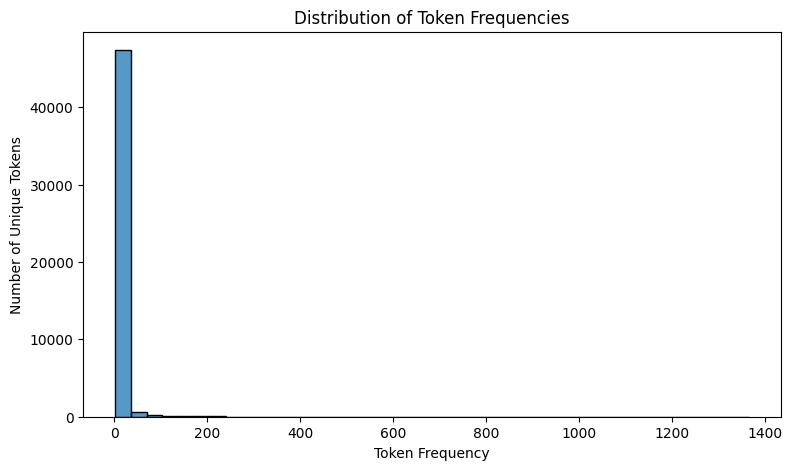

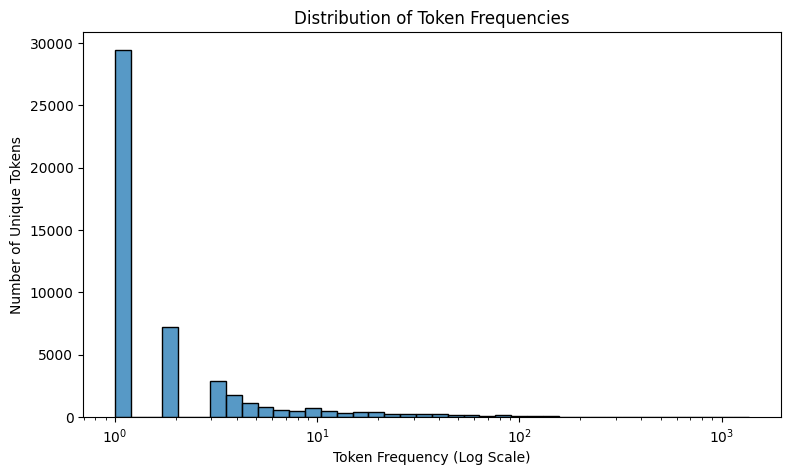


From the histogram, one can see that the frequency of occurrence for different tokens follows a
long-tailed, right-skewed distribution, with most tokens occurring relatively infrequently and a
smaller number occurring much more frequently. Thus, the distribution is concentrated among
lower-frequency tokens, with relatively few tokens exhibiting substantially higher occurrence counts.

R-squared Test: 0.6659
intercept: 0.4821
R-squared Train: 0.767
                Feature   Coefficient  Absolute Coefficient
835        intervention -1.259257e+00          1.259257e+00
740           localized  8.243505e-01          8.243505e-01
2362            thermal  7.470065e-01          7.470065e-01
851             crawler  6.961667e-01          6.961667e-01
1504  background-image: -6.229094e-01          6.229094e-01
...                 ...           ...                   ...
915                 300 -6.938894e-18          6.938894e-18
2642                301  3.469447e-18          3.469447e-18
1898   

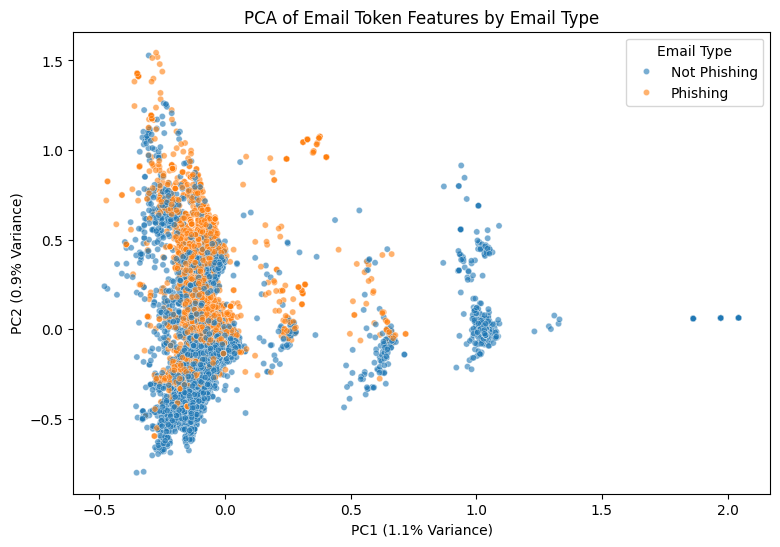


The PCA scatter displays significant overlap between phishing and non-phishing emails based on the
two Principal Components used--this is most evident near PC1 = 0, where several "Not Phishing"
and "Phishing" labels are clumped around the axis. Given that PCA explained variance was small
for both--1.1% and 0.9% for PC1 and PC2, respectively--these two components
account for only 2.0% of the overall variance in the token features. Other dimensions
therefore account for most of the remaining variance, although explained variance alone does not
necessarily indicate how well a component distinguishes phishing from non-phishing emails.
That being said, some distinct patterns appear; for example, non-phishing emails seem to dominate
clusters farther to the right of the PC1 axis. Additionally, phishing emails appear to be more
concentrated in upper portions of the PC2 cluster. As a whole, however, these two principal
components provide limited separation between phishing and non-phishing ema

In [6]:
# Your Phase 2 solution to the problem goes here.

# Phase 2: AI-assisted solution (run after assignment setup cells)

# Q1.

import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

# Convert token frequency list into DataFrame
df = pd.DataFrame(token_freq, columns=['Token Name', 'Token Frequency'])

# Display the 30 most common tokens without printing the entire frequency list
print("30 Most Common Tokens:")
print(token_freq[:30])

# Use the "Token Frequency" column for count; include all tokens (linear scale)
plt.figure(figsize=(9, 5))
sns.histplot(data=df, x='Token Frequency', bins=40, color='C0')
plt.title('Distribution of Token Frequencies')
plt.xlabel('Token Frequency')
plt.ylabel('Number of Unique Tokens')

# Display the plot
plt.show()

# Plot histogram of all token frequencies with logarithmic scale
plt.figure(figsize=(9, 5))
sns.histplot(data=df, x='Token Frequency', bins=40, log_scale=True)

# Label graph
plt.title('Distribution of Token Frequencies')
plt.xlabel('Token Frequency (Log Scale)')
plt.ylabel('Number of Unique Tokens')

# Display the plot
plt.show()


print("""
From the histogram, one can see that the frequency of occurrence for different tokens follows a
long-tailed, right-skewed distribution, with most tokens occurring relatively infrequently and a
smaller number occurring much more frequently. Thus, the distribution is concentrated among
lower-frequency tokens, with relatively few tokens exhibiting substantially higher occurrence counts.
""")

# Q2.

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

df_phish = pd.read_parquet("A05-pca/data/Phishing_clean.parquet")
df_phish.describe()

# X Features
X = df_phish.drop(columns='Email Type')

# y target vector Email Type
y = df_phish['Email Type']

# Perform 80/20 train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

sk_fit = LinearRegression().fit(X_train, y_train)

print("R-squared Test:", round(sk_fit.score(X_test, y_test), 4))
print("intercept:", round(sk_fit.intercept_, 4))
print("R-squared Train:", round(sk_fit.score(X_train, y_train), 4))

# Create a clean and sortable DataFrame
coef_df = pd.DataFrame({
    'Feature': sk_fit.feature_names_in_,
    'Coefficient': sk_fit.coef_
})
coef_df['Absolute Coefficient'] = coef_df['Coefficient'].abs()
coef_df = coef_df.sort_values(by='Absolute Coefficient', ascending=False)

print(coef_df)

coefficients = pd.Series(sk_fit.coef_, index=X_train.columns).round(4)
print(coefficients.sort_values(key=abs, ascending=False).head(10))

top_five_tokens = coef_df['Feature'].head(5).tolist()
print(f"""
The words with the largest coefficients in absolute value and, thus, the strongest influence on the
model's predictions, are: {', '.join(top_five_tokens)}. Positive coefficients increase the predicted
Email Type value (greater association with phishing), while negative coefficients decrease it
(greater association with non-phishing), holding other token features constant. Coefficients describe
fitted associations rather than necessarily indicating causal importance.
""")

# Q3.

from sklearn.decomposition import PCA
pca = PCA(n_components=2).fit(X)
X_pca_sklearn = pca.transform(X)
print("Rows and score columns:", X_pca_sklearn.shape)
print("Explained Variance Ratio:", pca.explained_variance_ratio_.round(3))

plt.figure(figsize=(9, 6))
sns.scatterplot(x=X_pca_sklearn[:, 0], y=X_pca_sklearn[:, 1],
                hue=pd.Series(y).map({0: 'Not Phishing', 1: 'Phishing'}),
                alpha=0.6, s=20) # Re-label ones and zeroes as "Phishing" and "Not Phishing"
plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.1%} Variance)')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.1%} Variance)')
plt.title('PCA of Email Token Features by Email Type')
plt.legend(title='Email Type')
plt.show()

print(f"""
The PCA scatter displays significant overlap between phishing and non-phishing emails based on the
two Principal Components used--this is most evident near PC1 = 0, where several "Not Phishing"
and "Phishing" labels are clumped around the axis. Given that PCA explained variance was small
for both--{pca.explained_variance_ratio_[0]:.1%} and {pca.explained_variance_ratio_[1]:.1%} for PC1 and PC2, respectively--these two components
account for only {pca.explained_variance_ratio_.sum():.1%} of the overall variance in the token features. Other dimensions
therefore account for most of the remaining variance, although explained variance alone does not
necessarily indicate how well a component distinguishes phishing from non-phishing emails.
That being said, some distinct patterns appear; for example, non-phishing emails seem to dominate
clusters farther to the right of the PC1 axis. Additionally, phishing emails appear to be more
concentrated in upper portions of the PC2 cluster. As a whole, however, these two principal
components provide limited separation between phishing and non-phishing emails.
""")

# Q4.

# X Features (Use X original data)
X_pca = X

# y target vector Email Type (same from earlier)
# Reuse the original training and test split from Q2

pca_2610 = PCA(n_components=2610)
X_train_pca = pca_2610.fit_transform(X_train)
X_test_pca = pca_2610.transform(X_test)
print("Rows and score columns:", X_train_pca.shape)

sk_fit_pca = LinearRegression().fit(X_train_pca, y_train)
print("R-squared Test:", round(sk_fit_pca.score(X_test_pca, y_test), 4))
print("intercept:", round(sk_fit_pca.intercept_, 4))
print("R-squared Train:", round(sk_fit_pca.score(X_train_pca, y_train), 4))

# Compare original and PCA-based regression performance
original_train_r2 = sk_fit.score(X_train, y_train)
original_test_r2 = sk_fit.score(X_test, y_test)
pca_train_r2 = sk_fit_pca.score(X_train_pca, y_train)
pca_test_r2 = sk_fit_pca.score(X_test_pca, y_test)

print("Original Train R-squared:", round(original_train_r2, 4))
print("Original Test R-squared:", round(original_test_r2, 4))
print("PCA Train R-squared:", round(pca_train_r2, 4))
print("PCA Test R-squared:", round(pca_test_r2, 4))
print("Train R-squared Difference:", round(pca_train_r2 - original_train_r2, 6))
print("Test R-squared Difference:", round(pca_test_r2 - original_test_r2, 6))

# How much original feature variance is retained by the 2,610 components?
print("Total Explained Variance (2610 PCs):",
      round(pca_2610.explained_variance_ratio_.sum() * 100, 2), "%")

# Interpret the numerical differences rather than assuming equality
r2_description = ("practically identical" if max(abs(pca_train_r2 - original_train_r2),
                                              abs(pca_test_r2 - original_test_r2)) < 0.01
                  else "not practically identical")
print(f"""
Compared with linear regression prior to principal components, the R-squared Test and Train Results
are {r2_description}, with training and testing R-squared differences of
{pca_train_r2 - original_train_r2:+.6f} and {pca_test_r2 - original_test_r2:+.6f}, respectively.
The intercept changed from {sk_fit.intercept_:.4f} to {sk_fit_pca.intercept_:.4f}; however, this is
primarily attributable to PCA centering the original features and does not independently indicate
a change in predictive performance.
""")


Q5. With thousands of dimensions, such as those found in this dataset, using PCA can reduce dimensionality by removing components that contribute less to the overall variance while retaining directions that explain the greatest variation. This may help filter out noise or less informative features, although lower variance does not necessarily imply lower predictive importance. Reducing the number of dimensions can also aid with computational costs during subsequent regression modeling and help reduce overfitting, particularly when the number of principal components retained is appreciably smaller than the original dataset's feature count. However, in this case, retaining 2,610 of the original 2,711 features represents only approximately 3.7% dimensionality reduction, meaning the computational and overfitting benefits may be modest.

### *Reflection on AI assistance
In your own words without generative AI.

This assignment's Phase 2 revisions were the most seamless integration thus far. They first targeted the major, necessary fixes to accurately answer the questions. They then prioritized improving the precision of my written responses, ensuring that I remained empirical in my interpretations without changing my underlying reasoning or observations. To be frank, the best part of these revisions was gaining a better understanding of the ML models being employed. Additionally, the AI was excellent at navigating formatting, spelling, and clarity changes—including visuals, grammatical errors, and labeling—so that the analysis was clean and highly readable.

In terms of mistakes, I do not believe there was anything substantial to point out apart from some out-of-scope suggestions (i.e., Changes 10 and 12 were not necessarily pertinent; Change 12, in my opinion, took away from my initial exploration of the data, even if the visual it critiqued was not the most essential). I was very intentional with the wording of my original prompt, so many of the mistakes I encountered in previous AI suggestions were not present. My only remaining concern is whether the AI overlooked conceptual mistakes because it was biased by my previous inputs (e.g., if I performed a split incorrectly, but the LLM only sought to improve efficiency rather than address the underlying logical issue in a PCA implementation).

For verification, I cross-verified outputs to see if they matched my initial calculations. For visuals, I made sure that each depiction maintained or bolstered the clarity of my original displays. For logic, I ensured that the syntax and organization matched my original code and our lectures' preferred style. Finally, I made sure that written responses minimally altered my interpretations and voice.